# CSET485 – AI and Society · Assignment #1
**Roll no:** s24bcau0054  →  last digit **4** → **German Credit Data (Statlog)**; random seed = last three digits `054` → `random_state = 54`.

Everything cited in the PDF report is produced by running this notebook top-to-bottom (`Kernel → Restart & Run All`).
Outputs written: `results.json`, `figures/*.png`, `tables/*.csv`.

**Outcome coding:** `approve = 1` if credit risk class is "good" (original label 1), `0` if "bad" (original label 2).
Following the assignment text literally, "high risk" below means "predicted score ≥ cut-off" for the *approval* score
(so a "high" flag here means high predicted approval propensity). This sign convention is discussed in the report.

In [1]:
import numpy as np, pandas as pd, json, os, warnings
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from scipy import stats
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
SEED = 54                       # last 3 digits of s24bcau0054 -> 054 -> 54
os.makedirs("figures", exist_ok=True); os.makedirs("tables", exist_ok=True)
R = {}                          # all numbers cited in the report are collected here

## 0. Data loading

In [2]:
cols = ["status","duration","credit_history","purpose","credit_amount","savings","employment","installment_rate",
        "personal_status_sex","other_debtors","residence_since","property","age","other_installment_plans","housing",
        "existing_credits","job","num_dependents","telephone","foreign_worker","target"]
UCI    = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"
MIRROR = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/german.csv"   # identical file, comma separated
try:
    raw = pd.read_csv(UCI, sep=r"\s+", header=None, names=cols)
    src = "UCI"
except Exception as e:
    raw = pd.read_csv(MIRROR, header=None, names=cols)
    src = "GitHub mirror of german.data"
assert raw.shape == (1000, 21)
print("source:", src, raw.shape)
raw.head()

source: GitHub mirror of german.data (1000, 21)


,status,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


## Data preprocessing (documented as required)

In [3]:
df = raw.copy()
# --- 1. Missing values --------------------------------------------------------------
R["n_missing"] = int(df.isna().sum().sum())
print("NaN cells:", R["n_missing"])
print("'Unknown' is coded as a real category in two columns: savings=A65 (%d rows), status=A14 'no checking account' (%d rows) -> kept as categories"
      % ((df.savings=="A65").sum(), (df.status=="A14").sum()))
# --- 2. Target + derived columns --------------------------------------------------------
df["approve"] = (df.target == 1).astype(int)          # 1 = approve (good), 0 = reject (bad)
df["female"]  = (df.personal_status_sex == "A92").astype(int)   # only female code present in this dataset (A92)
df["log_amt"] = np.log1p(df.credit_amount)
R["approve_rate"] = float(df.approve.mean()); R["female_share"] = float(df.female.mean())
print("approve rate %.3f | female share %.3f" % (R["approve_rate"], R["female_share"]))
# --- 3. Outliers (IQR rule) -----------------------------------------------------------
numeric_cols = ["duration","credit_amount","installment_rate","residence_since","age","existing_credits","num_dependents"]
rows = []
for c in numeric_cols:
    q1,q3 = df[c].quantile([.25,.75]); iqr = q3-q1
    n_out = int(((df[c] < q1-1.5*iqr) | (df[c] > q3+1.5*iqr)).sum())
    rows.append((c, df[c].min(), df[c].max(), round(df[c].skew(),2), n_out))
out_tab = pd.DataFrame(rows, columns=["variable","min","max","skew","n_IQR_outliers"])
print(out_tab); out_tab.to_csv("tables/outliers.csv", index=False)
R["outliers"] = out_tab.to_dict("records")
print("skew of log(credit_amount): %.2f" % df.log_amt.skew()); R["skew_logamt"] = float(df.log_amt.skew())
# decision: no row removed (all values are plausible loans/ages); the heavy right-skew of credit_amount is handled by log1p
# --- 4. Categorical encoding --------------------------------------------------------
num = ["duration","log_amt","installment_rate","residence_since","age","existing_credits","num_dependents"]
cat = ["status","credit_history","purpose","savings","employment","personal_status_sex","other_debtors","property",
       "other_installment_plans","housing","job","telephone","foreign_worker"]
# rare levels (<30 rows) are merged into 'rare' because they cause (quasi-)complete separation in an un-penalised logit
dfm = df.copy(); merged = {}
for c in cat:
    vc = dfm[c].value_counts(); rare = vc[vc < 30].index.tolist()
    if rare:
        merged[c] = {k:int(vc[k]) for k in rare}; dfm[c] = dfm[c].where(~dfm[c].isin(rare), "rare")
print("merged rare levels:", merged); R["merged_levels"] = merged
X_all = pd.get_dummies(dfm[num+cat], columns=cat, drop_first=True).astype(float)   # one-hot, first level dropped
y_all = df.approve
print("design matrix:", X_all.shape)
R["n_features"] = int(X_all.shape[1])
# --- 5. Split then scale (scaler fitted on TRAIN only: no leakage) --------------------------------------
Xtr, Xte, ytr, yte = train_test_split(X_all, y_all, test_size=0.30, random_state=SEED)
sc = StandardScaler().fit(Xtr[num])
Xtr_s, Xte_s = Xtr.copy(), Xte.copy()
Xtr_s[num] = sc.transform(Xtr[num]); Xte_s[num] = sc.transform(Xte[num])
R.update(n_train=len(Xtr), n_test=len(Xte), train_approve=float(ytr.mean()), test_approve=float(yte.mean()))
print("train", Xtr.shape, "test", Xte.shape, "| approve rate train %.3f test %.3f" % (ytr.mean(), yte.mean()))
# numeric columns are z-scored; dummies stay 0/1.  Coefficients in Parts 1, 2.2, 2.3, 2.4 are therefore per +1 SD.
Ctr, Cte = sm.add_constant(Xtr_s), sm.add_constant(Xte_s, has_constant="add")

NaN cells: 0
'Unknown' is coded as a real category in two columns: savings=A65 (183 rows), status=A14 'no checking account' (394 rows) -> kept as categories
approve rate 0.700 | female share 0.310
           variable  min    max  skew  n_IQR_outliers
0          duration    4     72  1.09              70
1     credit_amount  250  18424  1.95              72
2  installment_rate    1      4 -0.53               0
3   residence_since    1      4 -0.27               0
4               age   19     75  1.02              23
5  existing_credits    1      4  1.27               6
6    num_dependents    1      2  1.91             155
skew of log(credit_amount): 0.13
merged rare levels: {'purpose': {'A45': 22, 'A44': 12, 'A410': 12, 'A48': 9}, 'job': {'A171': 22}}
design matrix: (1000, 45)
train (700, 45) test (300, 45) | approve rate train 0.689 test 0.727


## Part 1 – Build

In [4]:
ols = sm.OLS(ytr, Ctr).fit()                    # Model A
lgt = sm.Logit(ytr, Ctr).fit(disp=0, maxiter=500)   # Model B
R["logit_converged"] = bool(lgt.mle_retvals["converged"])
p_A = ols.predict(Cte); p_B = lgt.predict(Cte)
med = float(np.median(p_A))
hiA = (p_A >= med).astype(int); hiB = (p_B >= 0.5).astype(int)
cm = pd.crosstab(hiA.rename("Model A (OLS >= median)"), hiB.rename("Model B (Logit >= 0.5)"))
print("logit converged:", R["logit_converged"]); print("OLS median prediction on test: %.4f" % med); print(cm)
mism = int((hiA != hiB).sum())
R["part1"] = dict(median_ols=med, cm=cm.values.tolist(), mismatch_n=mism, mismatch_pct=100*mism/len(yte),
    A_flag_rate=float(hiA.mean()), B_flag_rate=float(hiB.mean()),
    A_low_B_high=int(((hiA==0)&(hiB==1)).sum()), A_high_B_low=int(((hiA==1)&(hiB==0)).sum()),
    ols_min=float(p_A.min()), ols_max=float(p_A.max()), ols_outside01=int(((p_A<0)|(p_A>1)).sum()),
    spearman=float(stats.spearmanr(p_A, p_B)[0]), pearson=float(np.corrcoef(p_A, p_B)[0,1]),
    acc_A_med=float((hiA==yte).mean()), acc_B_05=float((hiB==yte).mean()),
    acc_train_B=float(((lgt.predict(Ctr)>=.5)==ytr).mean()),
    median_B=float(np.median(p_B)), mean_A=float(p_A.mean()), mean_B=float(p_B.mean()))
# control: if OLS is thresholded at 0.5 instead of its median, how many disagreements remain?
hiA05 = (p_A >= 0.5).astype(int)
R["part1"]["ctrl_mismatch_n"] = int((hiA05 != hiB).sum()); R["part1"]["ctrl_A05_flag_rate"] = float(hiA05.mean())
# and if both are cut at their own median?
hiB_med = (p_B >= np.median(p_B)).astype(int)
R["part1"]["ctrl_median_both_mismatch_n"] = int((hiA != hiB_med).sum())
from sklearn.metrics import roc_auc_score
R["part1"]["auc_B"] = float(roc_auc_score(yte, p_B)); R["part1"]["auc_A"] = float(roc_auc_score(yte, p_A))
R["part1"]["baseline_acc_always_approve"] = float(yte.mean())
R["part1"]["r2_train_A"] = float(ols.rsquared); R["part1"]["pseudo_r2_B"] = float(lgt.prsquared)
for k,v in R["part1"].items(): print(k, v)

logit converged: True
OLS median prediction on test: 0.7129
Model B (Logit >= 0.5)    0    1
Model A (OLS >= median)         
0                        79   71
1                         0  150
median_ols 0.7129041061785684
cm [[79, 71], [0, 150]]
mismatch_n 71
mismatch_pct 23.666666666666668
A_flag_rate 0.5
B_flag_rate 0.7366666666666667
A_low_B_high 71
A_high_B_low 0
ols_min 0.03294502471321372
ols_max 1.436852582127409
ols_outside01 34
spearman 0.9883536483738707
pearson 0.9429954505231594
acc_A_med 0.6666666666666666
acc_B_05 0.71
acc_train_B 0.8
median_B 0.7889483911927595
mean_A 0.7007544456686997
mean_B 0.7035671407466552
ctrl_mismatch_n 11
ctrl_A05_flag_rate 0.7666666666666667
ctrl_median_both_mismatch_n 10
auc_B 0.7582792571044976
auc_A 0.7626426493622734
baseline_acc_always_approve 0.7266666666666667
r2_train_A 0.3118831031191188
pseudo_r2_B 0.29761435134953296


## Part 2.1 – Simpson's-paradox hunt  (key predictor: `log_amt` = log(1+credit amount), controlling for duration, instalment rate, age)
Subgroup models use a compact predictor set in raw units (not z-scored) because n≈400–600 per subgroup and unpenalised logit with 48 dummies would not converge.

In [5]:
S_VARS = ["duration","log_amt","installment_rate","age"]
def logit_fit(d, vars_):
    return sm.Logit(d.approve, sm.add_constant(d[vars_].astype(float))).fit(disp=0)
def row(res, v):
    ci = res.conf_int().loc[v]; return dict(coef=float(res.params[v]), lo=float(ci[0]), hi=float(ci[1]), p=float(res.pvalues[v]))
# transparency: scan of candidate splits (this is a search, so we also report how many we looked at)
cands = {"female (A92) vs male":(df.female==1), "age < 25 vs >= 25":(df.age<25), "age <= 35 vs > 35":(df.age<=35),
         "foreign worker vs not":(df.foreign_worker=="A201"), "has telephone vs none":(df.telephone=="A192"),
         "owns housing vs other":(df.housing=="A152"), "skilled job vs unskilled":(df.job.isin(["A173","A174"])),
         "no checking acct vs has":(df.status=="A14"), "amount > median vs <=":(df.credit_amount>df.credit_amount.median())}
full = logit_fit(df, S_VARS); scan=[]
for k,m in cands.items():
    a, b = logit_fit(df[m], S_VARS), logit_fit(df[~m], S_VARS)
    ra, rb = row(a,"log_amt"), row(b,"log_amt")
    scan.append(dict(split=k, nA=int(m.sum()), coefA=ra["coef"], pA=ra["p"], nB=int((~m).sum()), coefB=rb["coef"], pB=rb["p"],
                     opposite_sign_both_sig = bool(np.sign(ra["coef"])!=np.sign(rb["coef"]) and ra["p"]<.05 and rb["p"]<.05)))
scan = pd.DataFrame(scan); print(scan.round(3)); scan.to_csv("tables/simpson_scan.csv", index=False)
R["simpson_scan"] = scan.to_dict("records"); R["n_splits_scanned"] = len(cands)

                      split   nA  coefA     pA   nB  coefB     pB  opposite_sign_both_sig
0      female (A92) vs male  310  0.014  0.955  690 -0.033  0.845                   False
1         age < 25 vs >= 25  149  0.261  0.467  851 -0.080  0.594                   False
2         age <= 35 vs > 35  588  0.244  0.186  412 -0.378  0.079                   False
3     foreign worker vs not  963  0.029  0.830   37 -0.577  0.687                   False
4     has telephone vs none  404 -0.801  0.000  596  0.591  0.003                    True
5     owns housing vs other  713  0.108  0.533  287 -0.026  0.909                   False
6  skilled job vs unskilled  778 -0.083  0.593  222  0.350  0.285                   False
7   no checking acct vs has  394 -0.807  0.014  606  0.108  0.497                   False
8     amount > median vs <=  500 -0.863  0.000  500  0.618  0.027                    True


            variable                model    coef      lo      hi       p
0           duration        Full (n=1000) -0.0376 -0.0536 -0.0216  0.0000
1           duration  A: no phone (n=596) -0.0655 -0.0887 -0.0423  0.0000
2           duration     B: phone (n=404) -0.0067 -0.0301  0.0168  0.5773
3            log_amt        Full (n=1000)  0.0125 -0.2558  0.2808  0.9273
4            log_amt  A: no phone (n=596)  0.5914  0.1993  0.9836  0.0031
5            log_amt     B: phone (n=404) -0.8009 -1.2169 -0.3849  0.0002
6   installment_rate        Full (n=1000) -0.1378 -0.2817  0.0060  0.0604
7   installment_rate  A: no phone (n=596) -0.1746 -0.3692  0.0200  0.0787
8   installment_rate     B: phone (n=404) -0.0331 -0.2572  0.1909  0.7720
9                age        Full (n=1000)  0.0194  0.0062  0.0326  0.0039
10               age  A: no phone (n=596)  0.0191  0.0018  0.0363  0.0301
11               age     B: phone (n=404)  0.0185 -0.0031  0.0401  0.0927
{'coef': -0.845111170911521, 'lo': -1.

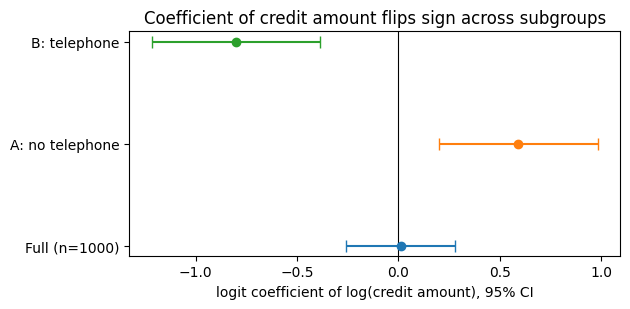

In [6]:
# Chosen split: telephone ownership (socio-economic marker).  A = no telephone, B = telephone registered
mask_B = (df.telephone == "A192"); dA, dB = df[~mask_B], df[mask_B]
resF, resA, resB = full, logit_fit(dA, S_VARS), logit_fit(dB, S_VARS)
tab = []
for v in S_VARS:
    for nm, r_ in [("Full (n=1000)", resF), ("A: no phone (n=%d)"%len(dA), resA), ("B: phone (n=%d)"%len(dB), resB)]:
        tab.append(dict(variable=v, model=nm, **row(r_, v)))
simp = pd.DataFrame(tab); print(simp.round(4)); simp.to_csv("tables/simpson_models.csv", index=False)
R["simpson"] = {v:{nm:row(r_,v) for nm,r_ in [("full",resF),("A",resA),("B",resB)]} for v in S_VARS}
R["simpson_n"] = dict(full=len(df), A=len(dA), B=len(dB), approve_A=float(dA.approve.mean()), approve_B=float(dB.approve.mean()))
# formal test of coefficient difference: interaction term log_amt x phone in pooled model
dI = df.copy(); dI["phone"]=mask_B.astype(int); dI["amt_x_phone"]=dI.log_amt*dI.phone
resI = logit_fit(dI, S_VARS+["phone","amt_x_phone"])
R["simpson_interaction"] = row(resI, "amt_x_phone")
# z-test of difference between the two subgroup coefficients
z = (resB.params["log_amt"]-resA.params["log_amt"])/np.sqrt(resA.bse["log_amt"]**2+resB.bse["log_amt"]**2)
R["simpson_z"] = float(z); R["simpson_z_p"] = float(2*(1-stats.norm.cdf(abs(z))))
# what drives the cancellation: mean amount/duration in each group, correlation of amount with outcome inside each group
R["simpson_desc"] = dict(
  mean_amt_A=float(dA.credit_amount.mean()), mean_amt_B=float(dB.credit_amount.mean()),
  mean_dur_A=float(dA.duration.mean()), mean_dur_B=float(dB.duration.mean()),
  corr_amt_dur_A=float(dA[["log_amt","duration"]].corr().iloc[0,1]), corr_amt_dur_B=float(dB[["log_amt","duration"]].corr().iloc[0,1]),
  raw_corr_amt_approve_full=float(df[["log_amt","approve"]].corr().iloc[0,1]),
  raw_corr_amt_approve_A=float(dA[["log_amt","approve"]].corr().iloc[0,1]), raw_corr_amt_approve_B=float(dB[["log_amt","approve"]].corr().iloc[0,1]))
print(R["simpson_interaction"], R["simpson_z"], R["simpson_z_p"]); print(R["simpson_desc"])
fig, ax = plt.subplots(figsize=(6.4,3.2))
for i,(nm,r_) in enumerate([("Full",R["simpson"]["log_amt"]["full"]),("A: no phone",R["simpson"]["log_amt"]["A"]),("B: phone",R["simpson"]["log_amt"]["B"])]):
    ax.errorbar(r_["coef"], i, xerr=[[r_["coef"]-r_["lo"]],[r_["hi"]-r_["coef"]]], fmt="o", capsize=4)
ax.axvline(0, color="k", lw=.8); ax.set_yticks([0,1,2]); ax.set_yticklabels(["Full (n=1000)","A: no telephone","B: telephone"])
ax.set_xlabel("logit coefficient of log(credit amount), 95% CI"); ax.set_title("Coefficient of credit amount flips sign across subgroups"); plt.tight_layout()
plt.savefig("figures/fig_simpson.png", dpi=170); plt.show()

## Part 2.2 – Omitted-variable bias  (dropped variable: `log_amt`, the loan amount)
Rationale (stated *before* fitting): amount is mechanically tied to duration and instalment size, so it is the most plausible confounder of those coefficients.

duration            0.64
log_amt             1.00
installment_rate   -0.27
residence_since     0.03
age                 0.00
existing_credits    0.01
num_dependents      0.08
Name: log_amt, dtype: float64
                      full  reduced  abs_change      pct
duration            -0.341   -0.532      -0.191  -55.869
installment_rate    -0.480   -0.361       0.119   24.838
residence_since     -0.044   -0.035       0.009   21.276
age                  0.211    0.204      -0.006   -3.056
existing_credits    -0.189   -0.203      -0.014   -7.187
num_dependents      -0.010   -0.023      -0.013 -127.039
foreign_worker_A202  1.927    1.752      -0.175   -9.085
purpose_A41          1.817    1.654      -0.163   -8.949
job_A174            -0.058   -0.177      -0.118 -202.917
{'full': 0.71, 'reduced': 0.7166666666666667} {'full': -304.9528440249729, 'reduced': -306.9221991276628, 'lr_stat': 3.9387102053798344, 'lr_p': 0.04718694328684603} {'duration': 0.19057149673748058, 'foreign_worker_A202': 0.

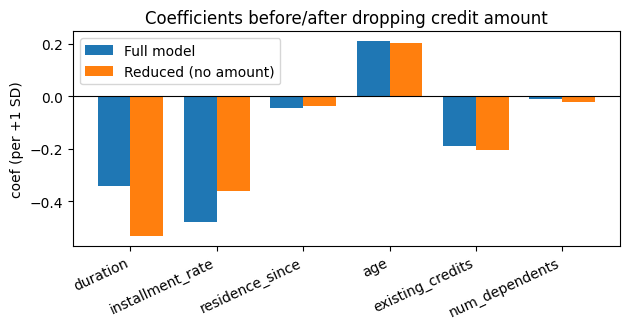

In [7]:
print(Xtr_s[num].corr().round(2)["log_amt"])
R["corr_logamt"] = Xtr_s[num].corr()["log_amt"].round(3).to_dict()
drop = "log_amt"; keep = [c for c in Ctr.columns if c != drop]
red = sm.Logit(ytr, Ctr[keep]).fit(disp=0, maxiter=500)
R["red_converged"] = bool(red.mle_retvals["converged"])
cmp_ = pd.DataFrame({"full": lgt.params[keep], "reduced": red.params[keep]})
cmp_["abs_change"] = cmp_.reduced - cmp_.full
cmp_["pct"] = 100*cmp_.abs_change/cmp_.full.abs()
cmp_.to_csv("tables/ovb_all.csv")
num_keep = [v for v in num if v != drop]
dummy_top = cmp_.drop(index=["const"]+num_keep).abs_change.abs().sort_values(ascending=False).index[:3].tolist()
ovb = cmp_.loc[num_keep + dummy_top]; print(ovb.round(3))
R["ovb"] = ovb.reset_index().rename(columns={"index":"variable"}).to_dict("records")
R["ovb_all_max_pct"] = cmp_.drop(index="const")["pct"].abs().sort_values(ascending=False).head(5).to_dict()
R["ovb_all_max_abs"] = cmp_.drop(index="const").abs_change.abs().sort_values(ascending=False).head(5).to_dict()
R["ovb_full_coef_dropped"] = float(lgt.params[drop])
R["ovb_acc"] = dict(full=float(((lgt.predict(Cte)>=.5)==yte).mean()), reduced=float(((red.predict(Cte[keep])>=.5)==yte).mean()))
R["ovb_llf"] = dict(full=float(lgt.llf), reduced=float(red.llf), lr_stat=float(2*(lgt.llf-red.llf)), lr_p=float(1-stats.chi2.cdf(2*(lgt.llf-red.llf),1)))
print(R["ovb_acc"], R["ovb_llf"], R["ovb_all_max_abs"])
fig, ax = plt.subplots(figsize=(6.4,3.4)); idx = np.arange(len(num_keep)); w=.38
ax.bar(idx-w/2, ovb.loc[num_keep,"full"], w, label="Full model"); ax.bar(idx+w/2, ovb.loc[num_keep,"reduced"], w, label="Reduced (no amount)")
ax.set_xticks(idx); ax.set_xticklabels(num_keep, rotation=25, ha="right"); ax.axhline(0,color="k",lw=.8); ax.legend(); ax.set_ylabel("coef (per +1 SD)")
ax.set_title("Coefficients before/after dropping credit amount"); plt.tight_layout(); plt.savefig("figures/fig_ovb.png", dpi=170); plt.show()

## Part 2.3 – Adversarial subset (confident and wrong)

In [8]:
yv = yte.values; pv = p_B.values
fp = (pv >= .75) & (yv == 0); fn = (pv <= .25) & (yv == 1); adv_mask = fp | fn
R["adv"] = dict(n_test=len(yv), n_fp=int(fp.sum()), n_fn=int(fn.sum()), n_total=int(adv_mask.sum()), pct=float(100*adv_mask.mean()),
                n_conf_high=int((pv>=.75).sum()), n_conf_low=int((pv<=.25).sum()))
adv_idx = Xte.index[adv_mask]
if len(adv_idx) > 50: adv_idx = pd.Index(np.random.RandomState(SEED).choice(adv_idx, 50, replace=False))
R["adv"]["n_used"] = len(adv_idx)
test_df = df.loc[Xte.index]; adv_df = df.loc[adv_idx]; rest_df = test_df.drop(index=adv_idx)
print(R["adv"])
# demographics
def demo(d): return dict(n=len(d), age_mean=float(d.age.mean()), age_median=float(d.age.median()), pct_under25=float(100*(d.age<25).mean()),
                         pct_over45=float(100*(d.age>45).mean()), pct_female=float(100*d.female.mean()), pct_foreign=float(100*(d.foreign_worker=="A201").mean()),
                         dur_mean=float(d.duration.mean()), amt_mean=float(d.credit_amount.mean()), approve_rate=float(100*d.approve.mean()))
R["adv_demo"] = dict(adv=demo(adv_df), test=demo(test_df), rest=demo(rest_df))
print(pd.DataFrame(R["adv_demo"]).round(2))
# which characteristic do they share?  compare share of each category level (and top-/bottom-tercile for numerics) vs rest of test set
rows=[]; trait_masks={}
for c in cat:
    for lev in dfm[c].unique():
        a = (dfm.loc[adv_idx,c]==lev).mean(); b = (dfm.loc[rest_df.index,c]==lev).mean()
        if (dfm[c]==lev).sum()>=30: rows.append((f"{c}={lev}", 100*a, 100*b, 100*(a-b))); trait_masks[f"{c}={lev}"] = (dfm[c]==lev)
for v in ["duration","credit_amount","age","installment_rate"]:
    hi = df[v].quantile(2/3); lo = df[v].quantile(1/3)
    for nm,f in [(f"{v}>{hi:.0f}",lambda s:s>hi),(f"{v}<={lo:.0f}",lambda s:s<=lo)]:
        a=f(df.loc[adv_idx,v]).mean(); b=f(df.loc[rest_df.index,v]).mean(); rows.append((nm,100*a,100*b,100*(a-b))); trait_masks[nm] = f(df[v])
cmpc = pd.DataFrame(rows, columns=["trait","pct_adv","pct_rest","diff"]).sort_values("diff", key=abs, ascending=False)
print(cmpc.head(12).round(1)); cmpc.to_csv("tables/adv_traits.csv", index=False)
from scipy.stats import fisher_exact
cmpc["fisher_p"] = [fisher_exact([[trait_masks[t].loc[adv_idx].sum(), len(adv_idx)-trait_masks[t].loc[adv_idx].sum()],
                                  [trait_masks[t].loc[rest_df.index].sum(), len(rest_df)-trait_masks[t].loc[rest_df.index].sum()]])[1] for t in cmpc.trait]
cmpc["n_traits_tested"] = len(cmpc)
print(cmpc.head(8).round(3)); R["adv_traits"] = cmpc.head(10).to_dict("records"); R["adv_n_traits_tested"] = len(cmpc)
# 'boost' diagnostic: big coefficients sitting on small categories
beta = lgt.params.drop("const"); dum = [c for c in beta.index if c not in num]
top_pos = beta[dum].sort_values(ascending=False).head(5).index.tolist(); top_neg = beta[dum].sort_values().head(5).index.tolist()
fpi, fni = Xte.index[fp], Xte.index[fn]; nonadv = Xte.index[~adv_mask]
R["adv_boost"] = dict(top_pos={k:dict(coef=float(beta[k]), train_n=int(Xtr[k].sum())) for k in top_pos},
    top_neg={k:dict(coef=float(beta[k]), train_n=int(Xtr[k].sum())) for k in top_neg},
    fp_mean_pos=float(Xte.loc[fpi, top_pos].sum(1).mean()), nonadv_mean_pos=float(Xte.loc[nonadv, top_pos].sum(1).mean()),
    fp_share_ge2_pos=float(100*(Xte.loc[fpi, top_pos].sum(1)>=2).mean()), nonadv_share_ge2_pos=float(100*(Xte.loc[nonadv, top_pos].sum(1)>=2).mean()),
    fn_mean_neg=float(Xte.loc[fni, top_neg].sum(1).mean()) if len(fni) else None, nonadv_mean_neg=float(Xte.loc[nonadv, top_neg].sum(1).mean()),
    fp_share_status_A14_or_hist_A34=float(100*((Xte.loc[fpi,"status_A14"]==1)|(Xte.loc[fpi,"credit_history_A34"]==1)).mean()),
    nonadv_share_status_A14_or_hist_A34=float(100*((Xte.loc[nonadv,"status_A14"]==1)|(Xte.loc[nonadv,"credit_history_A34"]==1)).mean()),
    fn_share_status_A11_and_sav_A61=float(100*((df.loc[fni,"status"]=="A11")&(df.loc[fni,"savings"]=="A61")).mean()) if len(fni) else None,
    nonadv_share_status_A11_and_sav_A61=float(100*((df.loc[nonadv,"status"]=="A11")&(df.loc[nonadv,"savings"]=="A61")).mean()),
    train_overfit_gap=float(R["part1"]["acc_train_B"]-R["part1"]["acc_B_05"]))
print(R["adv_boost"])
# split by error type
R["adv_split"] = dict(fp=demo(df.loc[Xte.index[fp]]) if fp.sum() else {}, fn=demo(df.loc[Xte.index[fn]]) if fn.sum() else {})
cmpc_fp = []; 
for c in ["status","credit_history","savings","employment","property","housing"]:
    for nm,msk in [("FP",fp),("FN",fn)]:
        if msk.sum(): cmpc_fp.append((nm,c,dfm.loc[Xte.index[msk],c].value_counts(normalize=True).round(2).to_dict()))
for r_ in cmpc_fp: print(r_)
R["adv_cat_dist"] = [dict(kind=a,var=b,dist=c) for a,b,c in cmpc_fp]
R["adv_mean_p"] = dict(fp_mean_p=float(pv[fp].mean()) if fp.sum() else None, fn_mean_p=float(pv[fn].mean()) if fn.sum() else None)
# overall calibration check on test set (is the model over-confident?)
bins=[0,.25,.5,.75,1.0001]; cal = pd.DataFrame({"p":pv,"y":yv}); cal["bin"]=pd.cut(cal.p,bins,right=False)
calt = cal.groupby("bin").agg(n=("y","size"), mean_p=("p","mean"), actual=("y","mean")); print(calt.round(3)); R["calibration"]=calt.reset_index().astype({"bin":str}).to_dict("records")
# the 3 largest-|z| coefficients of the logit (for the explanation)
R["top_coefs"] = lgt.params.drop("const").reindex(lgt.params.drop("const").abs().sort_values(ascending=False).index).head(10).round(3).to_dict()
print(R["top_coefs"])

{'n_test': 300, 'n_fp': 21, 'n_fn': 9, 'n_total': 30, 'pct': 10.0, 'n_conf_high': 169, 'n_conf_low': 24, 'n_used': 30}
                  adv     test     rest
n               30.00   300.00   270.00
age_mean        36.10    36.04    36.03
age_median      33.00    33.00    34.00
pct_under25     13.33    14.67    14.81
pct_over45      20.00    20.67    20.74
pct_female      36.67    30.33    29.63
pct_foreign     93.33    94.67    94.81
dur_mean        24.27    21.12    20.77
amt_mean      4177.90  3426.55  3343.07
approve_rate    30.00    72.67    77.41
                           trait  pct_adv  pct_rest  diff
33                 property=A121      6.7      28.9 -22.2
34                 property=A122     43.3      24.1  19.3
57           installment_rate<=2     53.3      35.6  17.8
51                  duration<=12     20.0      37.4 -17.4
52            credit_amount>3368     50.0      33.0  17.0
0                     status=A11     43.3      27.4  15.9
26       personal_status_sex=A93   

## Part 2.4 – Fairness trade-off sweep  (sensitive attribute: gender; Group A = female, Group B = male)

{'A': 91, 'B': 209, 'approve_A': 0.6483516483516484, 'approve_B': 0.7607655502392344}
      t   selA   selB     DP  TPR_A  TPR_B  FPR_A  FPR_B  TPR_ratio  FPR_ratio     EO  PPV_A  PPV_B     PP    acc   accA   accB  n_pos  FP   FN  cost_5to1
0  0.05  1.000  0.995  1.005  1.000  1.000  1.000   0.98      1.000      1.020  1.000  0.648  0.764  0.848  0.730  0.648  0.766    299  81    0        405
1  0.15  0.978  0.957  1.022  1.000  0.975  0.938   0.90      1.026      1.042  1.026  0.663  0.775  0.855  0.737  0.670  0.766    289  75    4        379
2  0.25  0.923  0.919  1.005  0.949  0.962  0.875   0.78      0.986      1.122  0.986  0.667  0.797  0.837  0.747  0.659  0.785    276  67    9        344
3  0.35  0.857  0.856  1.001  0.915  0.893  0.750   0.74      1.025      1.014  1.014  0.692  0.793  0.873  0.723  0.681  0.742    257  61   22        327
4  0.45  0.769  0.780  0.986  0.864  0.824  0.594   0.64      1.049      0.928  0.928  0.729  0.804  0.907  0.710  0.703  0.713    233  51 

      t  DP_lo  DP_hi  DP_nan_frac  EO_lo  EO_hi  EO_nan_frac  PP_lo  PP_hi  PP_nan_frac
0  0.05  1.000  1.015          0.0  1.000  1.000        0.000  0.717  1.007          0.0
1  0.15  0.983  1.061          0.0  0.916  1.050        0.000  0.728  1.011          0.0
2  0.25  0.928  1.078          0.0  0.913  1.045        0.000  0.713  0.991          0.0
3  0.35  0.897  1.106          0.0  0.770  1.098        0.000  0.741  1.031          0.0
4  0.45  0.859  1.129          0.0  0.660  1.121        0.000  0.769  1.070          0.0
5  0.55  0.786  1.109          0.0  0.562  1.109        0.000  0.759  1.060          0.0
6  0.65  0.726  1.094          0.0  0.483  1.072        0.000  0.768  1.056          0.0
7  0.75  0.696  1.122          0.0  0.347  1.129        0.000  0.789  1.070          0.0
8  0.85  0.632  1.210          0.0  0.412  1.189        0.028  0.766  1.019          0.0
9  0.95  0.403  1.322          0.0  0.000  1.225        0.138  0.572  1.069          0.0
{'DP': 0.35, 'EO': 0.

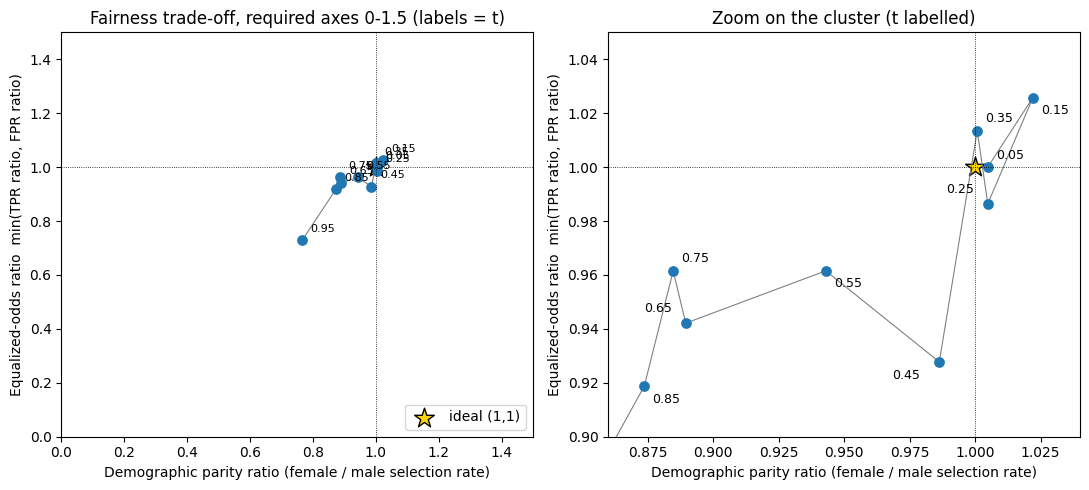

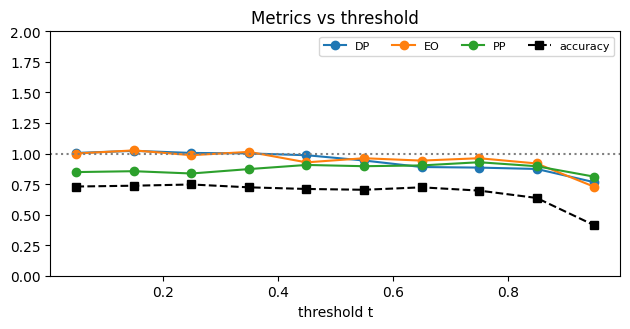

In [9]:
g = df.loc[Xte.index, "female"].values            # 1 = Group A (female)
R["fair_n"] = dict(A=int((g==1).sum()), B=int((g==0).sum()), approve_A=float(yv[g==1].mean()), approve_B=float(yv[g==0].mean()))
print(R["fair_n"])
def div(a,b): return np.nan if (b is None or b==0 or np.isnan(a) or np.isnan(b)) else a/b
def grp(yh, y):
    sel = yh.mean(); tpr = yh[y==1].mean() if (y==1).any() else np.nan; fpr = yh[y==0].mean() if (y==0).any() else np.nan
    ppv = y[yh==1].mean() if (yh==1).any() else np.nan; return sel, tpr, fpr, ppv
def fm(t, p, y, gg):
    yh = (p >= t).astype(int)
    sA,tA,fA,pA_ = grp(yh[gg==1], y[gg==1]); sB,tB,fB,pB_ = grp(yh[gg==0], y[gg==0])
    dp = div(sA,sB); r_t = div(tA,tB); r_f = div(fA,fB)
    eo = np.nan if (np.isnan(r_t) or np.isnan(r_f)) else min(r_t, r_f)
    return dict(selA=sA, selB=sB, DP=dp, TPR_A=tA, TPR_B=tB, FPR_A=fA, FPR_B=fB, TPR_ratio=r_t, FPR_ratio=r_f, EO=eo, PPV_A=pA_, PPV_B=pB_, PP=div(pA_,pB_), yh=yh)
THR = np.round(np.arange(0.05, 0.951, 0.10), 2)
rows=[]
for t in THR:
    m = fm(t, pv, yv, g); yh = m.pop("yh")
    fpn = int(((yh==1)&(yv==0)).sum()); fnn = int(((yh==0)&(yv==1)).sum())
    rows.append(dict(t=t, **m, acc=float((yh==yv).mean()), accA=float((yh[g==1]==yv[g==1]).mean()), accB=float((yh[g==0]==yv[g==0]).mean()),
                     n_pos=int(yh.sum()), FP=fpn, FN=fnn, cost_5to1=5*fpn+fnn))
sweep = pd.DataFrame(rows); print(sweep.round(3).to_string()); sweep.to_csv("tables/fairness_sweep.csv", index=False)
R["sweep"] = sweep.replace({np.nan:None}).to_dict("records")
# bootstrap 95% CIs (500 resamples of the 300 test rows, seed 54) -> are the ratios distinguishable from 1 at all?
rng = np.random.RandomState(SEED); BS = {t:{"DP":[],"EO":[],"PP":[]} for t in THR}
for _ in range(500):
    ii = rng.randint(0, len(yv), len(yv))
    for t in THR:
        m = fm(t, pv[ii], yv[ii], g[ii])
        for k in ("DP","EO","PP"): BS[t][k].append(m[k])
boot = []
for t in THR:
    d = dict(t=float(t))
    for k in ("DP","EO","PP"):
        a = np.array(BS[t][k], dtype=float); d[k+"_lo"], d[k+"_hi"] = [float(x) for x in np.nanpercentile(a,[2.5,97.5])]; d[k+"_nan_frac"]=float(np.isnan(a).mean())
    boot.append(d)
boot = pd.DataFrame(boot); print(boot.round(3).to_string()); boot.to_csv("tables/fairness_bootstrap.csv", index=False); R["boot"] = boot.to_dict("records")
R["majority_baseline_cost"] = float(5*((yv==0).sum()*0 + 0) + (yv==1).sum())   # reject everybody: FN=#good, FP=0
R["approve_all_cost"] = float(5*(yv==0).sum())                                    # approve everybody: FP=#bad
# distance from perfect fairness
sw = sweep.copy(); sw["dDP"]=(sw.DP-1).abs(); sw["dEO"]=(sw.EO-1).abs(); sw["dPP"]=(sw.PP-1).abs()
R["best_thr"] = dict(DP=float(sw.loc[sw.dDP.idxmin(),"t"]), EO=float(sw.loc[sw.dEO.idxmin(),"t"]), PP=float(sw.loc[sw.dPP.idxmin(),"t"]))
print(R["best_thr"])
# Trade-off chart: left = required axes (0-1.5); right = zoom on the cluster so every threshold label is legible
fig, axs = plt.subplots(1, 2, figsize=(11, 5.0)); v = sweep.dropna(subset=["DP","EO"]).reset_index(drop=True)
offs = [(6,6),(6,-12),(-30,8),(6,6),(-34,-12),(6,-12),(-30,8),(6,6),(6,-12),(6,6)]
for ax, zoom in zip(axs, [False, True]):
    ax.plot(v.DP, v.EO, "-", color="grey", lw=.8, zorder=1); ax.scatter(v.DP, v.EO, s=45, zorder=2)
    for i,r_ in v.iterrows():
        if zoom and not (0.86 <= r_.DP <= 1.04 and 0.90 <= r_.EO <= 1.05): continue
        ax.annotate(f"{r_.t:.2f}", (r_.DP, r_.EO), textcoords="offset points", xytext=offs[i] if zoom else (6,6), fontsize=9 if zoom else 8)
    ax.scatter([1],[1], marker="*", s=220, color="gold", edgecolor="k", zorder=0, label="ideal (1,1)")
    ax.axvline(1, ls=":", color="k", lw=.6); ax.axhline(1, ls=":", color="k", lw=.6)
    if zoom: ax.set_xlim(0.86,1.04); ax.set_ylim(0.90,1.05); ax.set_title("Zoom on the cluster (t labelled)")
    else:    ax.set_xlim(0,1.5); ax.set_ylim(0,1.5); ax.set_title("Fairness trade-off, required axes 0-1.5 (labels = t)"); ax.legend(loc="lower right")
    ax.set_xlabel("Demographic parity ratio (female / male selection rate)"); ax.set_ylabel("Equalized-odds ratio  min(TPR ratio, FPR ratio)")
plt.tight_layout(); plt.savefig("figures/fig_tradeoff.png", dpi=170); plt.show()
R["outside_axes"] = sweep[(sweep.DP>1.5)|(sweep.EO>1.5)|(sweep.DP<0)|(sweep.EO<0)][["t","DP","EO"]].to_dict("records")
fig, ax = plt.subplots(figsize=(6.4,3.4))
for k in ["DP","EO","PP"]: ax.plot(sweep.t, sweep[k], "o-", label=k)
ax.plot(sweep.t, sweep.acc, "s--", color="k", label="accuracy"); ax.axhline(1, ls=":", color="grey")
ax.set_xlabel("threshold t"); ax.set_ylim(0,2); ax.legend(ncol=4, fontsize=8); ax.set_title("Metrics vs threshold"); plt.tight_layout(); plt.savefig("figures/fig_sweep.png", dpi=170); plt.show()

## Save everything

In [10]:
class Enc(json.JSONEncoder):
    def default(self, o):
        if isinstance(o,(np.integer,)): return int(o)
        if isinstance(o,(np.floating,)): return None if np.isnan(o) else float(o)
        if isinstance(o,(np.bool_,)): return bool(o)
        return super().default(o)
json.dump(R, open("results.json","w"), cls=Enc, indent=1)
print("saved results.json with", len(R), "top-level keys")

saved results.json with 46 top-level keys
